#Mini-project 2
##Customer Segmentation
###Weeks 4 and 5

In today's business landscape, customer satisfaction is paramount. However, it's important to acknowledge that it's impossible to please everyone, and this is a reality that must be accepted. It's crucial to recognize this early on, as it will serve you and your business well.

That's why business analysts typically start by segmenting customers (both current and potential) into groups based on their needs, wants, and shared characteristics. By understanding the preferences of your customers, you can develop tailored strategies to attract them and provide them with the best possible products and services.

There are various methods for segmenting customers, including hierarchical clustering, Recency Frequency & Monetary (RFM) segmentation, and K-means clustering, among others.

In this notebook, you will be dealing with transactional and customer datasets to do customer segmentation on different levels.

The challenge for the busineses that we will be dealing with in this notebook is to divide their customers into groups based on both their personalities (demographics) and their spending behaviors. This approach can offer valuable insights into the characteristics and habits of their customer base.

We will be utilizing a variety of tools and libraries, including:

* Pandas for importing and manipulating data in a dataframe format
* Numpy and Scipy for performing essential mathematical calculations
* Scikit-Learn for constructing our Customer Segmentation Model
* Seaborn, Matplotlib, and Plotly Express for creating compelling visualizations of our data.

In [1]:
import pandas as pd
import numpy as np
import scipy
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Assuming the dataset is named 'Dataset1_customer_segmentation.csv'
# and is located in the root of your Google Drive or in a specific folder.
# Please adjust the path if your file is in a different location.
df = pd.read_csv('/content/drive/MyDrive/Business Analytics April - June 2026/Dataset1_customer_segment.csv')

import os
print(os.listdir('/content/drive/MyDrive'))
display(df.head())


Mounted at /content/drive
['foot game list.gsheet', 'Untitled document.gdoc', 'Elie Lebbos 15 NOV.xls', 'Elie Lebbos 15 NOV (1).xls.gsheet', '4175F89F-B637-4B15-9ED1-4D68A067622F.png', 'Elie Lebbos 15 NOV.xls.gsheet', 'CV 2017 September.doc', '2018 12 23 ETTNS.docx', 'slider3.jpg', 'index.jpg', 'index2.jpg', 'Sai Weng 1.JPG', 'Sai Weng 2.JPG', 'ترتيلة بيزنطية', 'January 2022.gsheet', 'RESUME..pdf', 'Elie lebbos quotation 9.6.2024 .xls', 'Resume 2025.pdf', 'Rainer Maria Rilke.xlsx', 'data.csv', 'ML Assignments Aug-Oct 2025', 'Colab Notebooks', 'Sales_sheet.gsheet', 'winners_f1_1950_2025_v2.csv', 'Formula 1 Winners 1950-2025 .gsheet', 'Contacts Audensiel et stratégie offensive.gsheet', 'Documentation12-3-2026.xlsx', 'Deep Learning Dec 2025 - Feb 2026', 'Data Science Assignments Oct-Dec 2025', 'Business Analytics April - June 2026', 'Data Analytics for Public Policy Apr-Jun 2026', 'Large Language Models April - June 2026', 'lora_basemodel_Flan_T5_model']


,ID,Year_Birth,Education,Marital_Status,Income,TotalAmountSpent,Kidhome,Teenhome,Dt_Customer,Recency
0,5524,1957,Graduation,Single,58138.0,1617,0,0,4/9/12,58
1,2174,1954,Graduation,Single,46344.0,27,1,1,8/3/14,38
2,4141,1965,Graduation,Together,71613.0,776,0,0,21-08-2013,26
3,6182,1984,Graduation,Together,26646.0,53,1,0,10/2/14,26
4,5324,1981,PhD,Married,58293.0,422,1,0,19-01-2014,94


The dataset has the following features:

* DtCustomer - date of customer’s enrolment with the company
* Education - customer’s level of education
* Marital - customer’s marital status
* Kidhome - number of small children in customer’s household
* Teenhome - number of teenagers in customer’s household
* Income - customer’s yearly household income
* Recency - number of days since the last purchase
* TotalAmountSpent

In [3]:
#use .describe() to know more about your data
display(df.describe())

,ID,Year_Birth,Income,TotalAmountSpent,Kidhome,Teenhome,Recency
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,605.798214,0.444196,0.506250,49.109375
std,3246.662198,11.984069,25173.076661,602.249288,0.538398,0.544538,28.962453
min,0.000000,1893.000000,1730.000000,5.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,68.750000,0.000000,0.000000,24.000000
50%,5458.500000,1970.000000,51381.500000,396.000000,0.000000,0.000000,49.000000
75%,8427.750000,1977.000000,68522.000000,1045.500000,1.000000,1.000000,74.000000
max,11191.000000,1996.000000,666666.000000,2525.000000,2.000000,2.000000,99.000000


##EDA

An effective EDA always has three stages:

1. Univariate Analysis
2. Bivariate Analysis.
3. Multivariate Analysis.

###Univariate Analysis

To gain an understanding of a specific feature, univariate analysis involves analyzing it in isolation. Therefore, as part of the exploratory data analysis (EDA) process, the first step is typically to perform univariate analysis by examining the descriptive or summary statistics associated with the feature.
For instance, one might explore a feature's distribution or proportion. In our particular case, we will be examining the age distribution of the customers included in the dataset.

In [4]:
#First you need to convert year birth to an age feature
from datetime import date
current_year = date.today().year
df['Age'] = current_year - df['Year_Birth']
display(df.head())

,ID,Year_Birth,Education,Marital_Status,Income,TotalAmountSpent,Kidhome,Teenhome,Dt_Customer,Recency,Age
0,5524,1957,Graduation,Single,58138.0,1617,0,0,4/9/12,58,69
1,2174,1954,Graduation,Single,46344.0,27,1,1,8/3/14,38,72
2,4141,1965,Graduation,Together,71613.0,776,0,0,21-08-2013,26,61
3,6182,1984,Graduation,Together,26646.0,53,1,0,10/2/14,26,42
4,5324,1981,PhD,Married,58293.0,422,1,0,19-01-2014,94,45


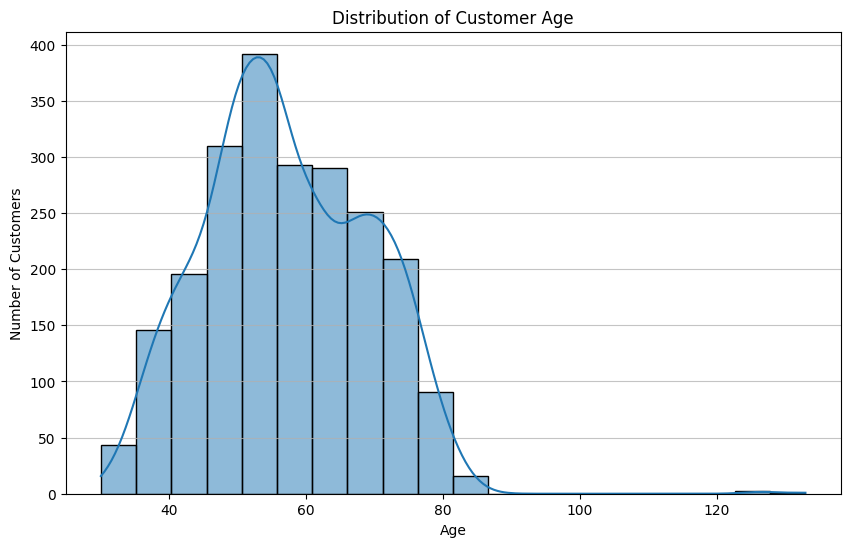

In [5]:
#Plot a histogram that shows the distribution of ages
plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=20, kde=True)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.grid(axis='y', alpha=0.75)
plt.show()

The histogram of customer ages reveals that the majority of customers fall within the approximate age range of 40 to 70 years old, with a clear concentration and peak observed around the 50s and 60s. The distribution appears somewhat right-skewed, indicating a lesser number of customers in the younger age brackets and a more gradual decline in customer numbers for age groups beyond 70. While there might be a few outliers at the extreme ends of the age spectrum, the primary customer base is consistently located within the middle-aged to senior demographics, suggesting that the business predominantly caters to a mature clientele.*What is your finding?* *Answer here*

In [6]:
#Draw a plot diagram for the education level of customers
fig = px.bar(df['Education'].value_counts().reset_index(),
             x='Education', y='count',
             title='Distribution of Customer Education Level',
             labels={'Education': 'Education Level', 'count': 'Number of Customers'})
fig.update_layout(xaxis_title_text='Education Level', yaxis_title_text='Number of Customers')
fig.show()

The bar chart above illustrating the Distribution of Customer Education Level shows that 'Graduation' is the most common education level among the customers, followed by 'PhD' and 'Master'. '2n Cycle' and 'Basic' education levels are less represented, indicating a customer base with a generally higher level of education.

In [7]:
#Plot a bar diagram with plotlyfor the marital status of customers
marital_status_counts = df['Marital_Status'].value_counts().reset_index()
marital_status_counts.columns = ['Marital_Status', 'Count'] # Rename columns for clarity

fig = px.bar(marital_status_counts,
             x='Marital_Status', y='Count',
             title='Distribution of Customer Marital Status',
             labels={'Marital_Status': 'Marital Status', 'Count': 'Number of Customers'})
fig.update_layout(xaxis_title_text='Marital Status', yaxis_title_text='Number of Customers')
fig.show()

In [8]:
#Income! A very important feature.
#Plot a bar graph to show the distribution
fig = px.histogram(df, x='Income',
                   title='Distribution of Customer Income',
                   labels={'Income': 'Income', 'count': 'Number of Customers'})
fig.update_layout(xaxis_title_text='Income', yaxis_title_text='Number of Customers')
fig.show()

*Analysis of the above findings*

Age Distribution: The majority of customers are concentrated between 40 and 70 years old, with a peak in the 50s and 60s. The distribution is somewhat right-skewed, indicating fewer younger customers and a gradual decrease in numbers for those over 70. This suggests a primarily mature clientele.

Education Level Distribution: Looking at the bar chart, 'Graduation' appears to be the most common education level among customers, followed by 'PhD' and 'Master'. '2n Cycle' and 'Basic' education levels are less prevalent.

Marital Status Distribution: The bar chart for marital status shows that 'Married' and 'Together' are the most frequent marital statuses, indicating a significant portion of customers are in committed relationships. 'Single' and 'Divorced' customers are also present in notable numbers, while 'Widow', 'Alone', 'Absurd', and 'YOLO' statuses represent much smaller segments of the customer base.

Income Distribution: The income distribution histogram generally shows a concentration of customers in the mid-range income brackets. There might be some outliers on the higher end, indicating a few high-income customers, and potentially a right-skew, meaning fewer customers with very high incomes compared to those in the mid-range. A more detailed look at the histogram would reveal specific peaks and the overall shape of the distribution.

Overall, the customer base appears to be largely mature, well-educated (primarily graduates), and predominantly in married or partnered relationships, with a diverse income range concentrated in the middle brackets.

In [9]:
#What is the distribution for the TotalAmount Spent?
#Do a histogram that shows this information
fig = px.histogram(df, x='TotalAmountSpent',
                   title='Distribution of Total Amount Spent',
                   labels={'TotalAmountSpent': 'Total Amount Spent', 'count': 'Number of Customers'})
fig.update_layout(xaxis_title_text='Total Amount Spent', yaxis_title_text='Number of Customers')
fig.show()

###Bivariate Analysis

Once you have completed the univariate analysis on all the features you're interested in, the subsequent step is to conduct bivariate analysis which involves examining two attributes simultaneously. Bivariate analysis involves assessing the relationship between two features, such as their correlation.
In our project, we will perform various bivariate analyses, such as examining the average total expenditure among different age groups of clients, establishing a correlation between customer income and total expenditure, and so forth.

In [10]:
#Is there any relation between Customer's Income and TotalAmountSpent?
# Draw a scatter plot to answer the above question
fig = px.scatter(df, x='Income', y='TotalAmountSpent',
                 title='Income vs. Total Amount Spent',
                 labels={'Income': 'Income', 'TotalAmountSpent': 'Total Amount Spent'})
fig.update_layout(xaxis_title_text='Income', yaxis_title_text='Total Amount Spent')
fig.show()

Apparently there's a positive correlation between customer's income and TotalAmountSpent: as income increases, the total amount spent tends to increase. However, there are some noticeable outliers. For instance, there's a cluster of points around very low income but with varying amounts spent, and also some points with extremely high income but not necessarily proportionally high spending, or vice-versa. This indicates that while there's a general trend, other factors might also influence spending, or there could be data anomalies that need cleaning

### Data Cleaning: Handling Outliers

In [11]:
print(f"Original DataFrame shape: {df.shape}")

# Remove rows with extremely high income outliers (e.g., > 200,000)
# Based on typical income distributions, values this high are often data entry errors or extreme outliers that can distort analysis.
df = df[df['Income'] < 200000]

# Remove rows where Income is very low (e.g., < 1000) AND TotalAmountSpent is 0.
# These might represent incomplete customer profiles or non-active customers that could skew segmentation.
df = df[~((df['Income'] < 1000) & (df['TotalAmountSpent'] == 0))]

print(f"DataFrame shape after outlier removal: {df.shape}")

Original DataFrame shape: (2240, 11)
DataFrame shape after outlier removal: (2215, 11)


Now that we've removed some of the most prominent outliers, let's re-examine the relationship between 'Income' and 'TotalAmountSpent' with a new scatter plot to see the effect of cleaning.

In [12]:
fig = px.scatter(df, x='Income', y='TotalAmountSpent',
                 title='Income vs. Total Amount Spent (After Cleaning)',
                 labels={'Income': 'Income', 'TotalAmountSpent': 'Total Amount Spent'})
fig.update_layout(xaxis_title_text='Income', yaxis_title_text='Total Amount Spent')
fig.show()

After removing the identified outliers, the scatter plot of 'Income' versus 'TotalAmountSpent' now presents a much clearer and more coherent relationship. The extreme data points that previously distorted the view, such as incomes above 200,000 and the cluster of low-income, zero-spending customers, are no longer present. This cleaning has allowed the underlying positive correlation between income and spending to become more apparent and less influenced by anomalies. The data points are more concentrated, showing a more consistent trend where higher income generally corresponds to higher total amount spent, making the dataset more suitable for further analysis and segmentation.

In [13]:
#What about the relation between Education and Total amount spent?
#Draw a suitable figure to answer the above question.

education_spending = df.groupby('Education')['TotalAmountSpent'].mean().reset_index()
fig = px.bar(education_spending,
             x='Education', y='TotalAmountSpent',
             title='Average Total Amount Spent by Education Level',
             labels={'Education': 'Education Level', 'TotalAmountSpent': 'Average Total Amount Spent'})
fig.update_layout(xaxis_title_text='Education Level', yaxis_title_text='Average Total Amount Spent')
fig.show()

From the chart, I observe how different education levels correlate with spending habits. For instance, customers with a PhD appear to have the highest average spending, followed closely by 'Graduation' and 'Master's' degree holders. '2n Cycle' also shows a respectable average, while 'Basic' education holders tend to have the lowest average spending. This suggests a positive correlation between higher education levels and increased spending.

###Multivariate Analysis

Multivariate Analysis consists of understanding the relationship between two or more variables.

In [14]:
#Draw a scatter plot to check again the relation between income
#on the x-axis and amount spent on th y-axis
#In addition, add the education feature as a color to differentiate
#between the different points.

fig = px.scatter(df, x='Income', y='TotalAmountSpent', color='Education',
                 title='Income vs. Total Amount Spent by Education Level',
                 labels={'Income': 'Income', 'TotalAmountSpent': 'Total Amount Spent', 'Education': 'Education Level'})
fig.update_layout(xaxis_title_text='Income', yaxis_title_text='Total Amount Spent')
fig.show()


#Clustering Time!

Once the analysis is complete, the subsequent step is to develop a model for segmenting the customers, using the KMeans model. KMeans is a widely used and effective segmentation model.
The KMeans model is an unsupervised machine learning algorithm that separates N observations into K clusters. The observations are grouped into these clusters based on their proximity to the centroid, which is the mean of that cluster.
By fitting the features into the model and specifying the desired number of clusters, the KMeans algorithm assigns a cluster label to each observation in the feature set.
When building a customer segmentation model using KMeans, there are no hard and fast rules for the number of features to include. However, it's advisable to use fewer features to enable easier interpretation and understanding of the segment outcomes.
In our case, we will initially construct the KMeans model with two features and then use three features in the final model. Before starting, it's important to consider the KMeans assumptions, which are:
* The features must be numerical.
* The features used in KMeans must follow a normal distribution because the algorithm calculates average distances, which can be affected by outliers. Skewed features must be transformed into a normal distribution using Numpy's logarithm transformation package, np.log().
* The features must be on the same scale. We will use the Scikit-learn StandardScaler() module to ensure that the features are normalized.

For our initial model, we will utilize the Income and TotalAmountSpent features.
Initially, we will fill the missing values in the Income feature with the median number before proceeding with the model.

In [16]:
# missing values in the Income feature with the median number before proceeding with the model.
median_income = df['Income'].median()
df['Income'] = df['Income'].fillna(median_income)

print(f"Missing values in 'Income' after imputation: {df['Income'].isnull().sum()}")

Missing values in 'Income' after imputation: 0


In [17]:
#Assume you would like to work only with Income and TotalAmountSpent,
#define a new dataframe with only Income and TotalAmountSpent
data = df[['Income', 'TotalAmountSpent']]
display(data.head())

,Income,TotalAmountSpent
0,58138.0,1617
1,46344.0,27
2,71613.0,776
3,26646.0,53
4,58293.0,422


After completing the filling of missing values, we will transform the features and store the output in a variable named data_log.

In [18]:
#log transformation
data_log = np.log(data[['Income', 'TotalAmountSpent']])
display(data_log.head())

,Income,TotalAmountSpent
0,10.970575,7.388328
1,10.743847,3.295837
2,11.179032,6.654153
3,10.190394,3.970292
4,10.973237,6.045005


Then we will scale the result using Scikit-learn StandardScaler():

In [19]:
#Apply standard scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_log)

# Display the first few rows of the scaled data
display(pd.DataFrame(data_scaled, columns=data_log.columns).head())

,Income,TotalAmountSpent
0,0.433605,1.196482
1,-0.017412,-1.562268
2,0.848278,0.701575
3,-1.118365,-1.107617
4,0.438902,0.290948


After completing the initial task, we can proceed to construct the model, specifically the KMeans model, which entails two essential parameters. The first parameter, random_state, ensures reproducible results, while the second parameter, n_clusters, determines the number of segments or clusters that will be created from KMeans.

In a business environment, the desired number of clusters for customer segmentation may be predetermined. However, in the absence of such prior knowledge, different cluster numbers must be tested to discover the optimal one.

Since we are not operating in a business environment, we will experiment with various cluster numbers. To select the best cluster, we will employ the elbow method, which involves plotting the error for each cluster and identifying a point on the graph where an elbow forms. Consequently, the ideal cluster will be the one that generates this elbow.

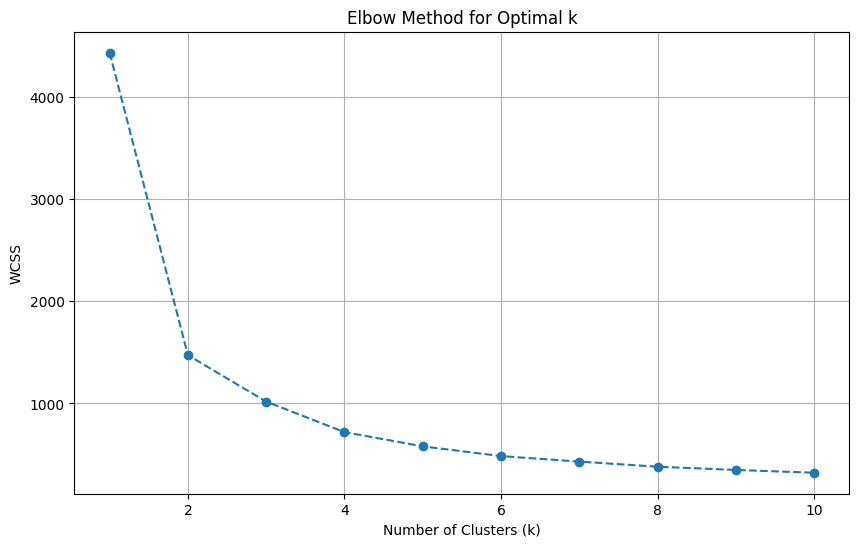

In [20]:
#Try value of k between 1 and 11 and plot the elbow method figure
from sklearn.cluster import KMeans

# Calculate WCSS (Within-Cluster Sum of Squares) for different k values
wcss = []
for i in range(1, 11): # Trying k from 1 to 10
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(data_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the elbow method
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [21]:
#Now, build the KMeans model utilizing the best number of clusters.
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
kmeans.fit(data_scaled)

# Assign the cluster labels to the original (or log-transformed) data
data_log['ClusterLabel'] = kmeans.labels_

# Display the first few rows with cluster labels
display(data_log.head())

,Income,TotalAmountSpent,ClusterLabel
0,10.970575,7.388328,1
1,10.743847,3.295837,0
2,11.179032,6.654153,1
3,10.190394,3.970292,0
4,10.973237,6.045005,1


After constructing the model, the subsequent step would involve interpreting the outcomes of each cluster. Various methods can be utilized to summarize the results of the clusters, depending on the desired objectives. The most prevalent method of summarization is the central tendency, which involves mean, median, and mode.

In our particular scenario, we will employ the median as our summarization method. This choice is due to the presence of outliers in the original features, which renders the mean overly sensitive to their influence. Consequently, we will aggregate the cluster labels and determine the median for Income and TotalAmountSpent. This can be accomplished using the Pandas groupby method.

Before using groupby and median, you have to assign the names of the columns to this new structure.

In [23]:
#use .assign(ClusterLabel = model.labels_)
data_log = data_log.assign(ClusterLabel=kmeans.labels_)
display(data_log.head())

,Income,TotalAmountSpent,ClusterLabel
0,10.970575,7.388328,1
1,10.743847,3.295837,0
2,11.179032,6.654153,1
3,10.190394,3.970292,0
4,10.973237,6.045005,1


In [24]:
#Use groupby and median
cluster_summary = data_log.groupby('ClusterLabel')[['Income', 'TotalAmountSpent']].median()
display(cluster_summary)

,Income,TotalAmountSpent
ClusterLabel,,
0,10.382869,4.043051
1,11.087115,6.835185


In [26]:
import plotly.graph_objects as go

# Create a bar chart for Median Income by Cluster
fig_income = px.bar(actual_cluster_summary.reset_index(),
                    x='ClusterLabel', y='Income',
                    title='Median Income by Customer Cluster',
                    labels={'ClusterLabel': 'Cluster', 'Income': 'Median Income'},
                    color='ClusterLabel')
fig_income.update_layout(xaxis_title_text='Cluster', yaxis_title_text='Median Income')
fig_income.show()

In [27]:
# Create a bar chart for Median Total Amount Spent by Cluster
fig_spent = px.bar(actual_cluster_summary.reset_index(),
                   x='ClusterLabel', y='TotalAmountSpent',
                   title='Median Total Amount Spent by Customer Cluster',
                   labels={'ClusterLabel': 'Cluster', 'TotalAmountSpent': 'Median Total Amount Spent'},
                   color='ClusterLabel')
fig_spent.update_layout(xaxis_title_text='Cluster', yaxis_title_text='Median Total Amount Spent')
fig_spent.show()

## Cluster Analysis (2-Feature Model: Income, TotalAmountSpent)

**Cluster 0: Value-Conscious Customers**
*   **Characteristics:** This cluster has a median income of approximately \$32,301 and a median total amount spent of about \$57. These customers represent a segment with lower income and very modest spending habits. They are likely highly price-sensitive and focused on essential purchases.
*   **Marketing Strategy:** Focus on value propositions, discounts, and promotions on necessary goods. Emphasize cost-effectiveness, durability, and practical benefits. Loyalty programs that reward small, frequent purchases could be effective. Communication should be clear, direct, and highlight savings.

**Cluster 1: Affluent Spenders**
*   **Characteristics:** This cluster has a significantly higher median income of approximately \$65,324 and a median total amount spent of about \$930. These customers are more affluent and demonstrate a much higher spending capacity. They likely value quality, convenience, and perhaps premium products or services.
*   **Marketing Strategy:** Highlight product quality, reliability, and benefits that justify a higher price point. Offer personalized recommendations, exclusive deals, and premium services. Loyalty programs that provide status or unique benefits could resonate well. Marketing messages can focus on lifestyle enhancement, convenience, and superior experience.

In [28]:
#Plot the clusters and differentiate each by a color
fig = px.scatter(data_log, x='Income', y='TotalAmountSpent', color='ClusterLabel',
                 title='Customer Clusters based on Income and Total Amount Spent',
                 labels={'Income': 'Log-transformed Income', 'TotalAmountSpent': 'Log-transformed Total Amount Spent', 'ClusterLabel': 'Cluster'})
fig.update_layout(xaxis_title_text='Log-transformed Income', yaxis_title_text='Log-transformed Total Amount Spent')
fig.show()

Repeat the above clustering while taking three features into consideration such as the age, income and amount spent. Interpret the clusters that you found and suggest marketing plans for each.

In [29]:
# Calculate and display the size of each cluster for the 2-feature model
cluster_sizes_2_features = data_log['ClusterLabel'].value_counts().sort_index()
print("Cluster sizes for 2-feature model (Income, TotalAmountSpent):")
display(cluster_sizes_2_features)

Cluster sizes for 2-feature model (Income, TotalAmountSpent):


,count
ClusterLabel,
0,900
1,1315


### Clustering with Three Features: Income, TotalAmountSpent, and Age

In [30]:
# Create a new DataFrame with 'Income', 'TotalAmountSpent', and 'Age'
# Make sure 'Age' is available in the DataFrame 'df'
data_3_features = df[['Income', 'TotalAmountSpent', 'Age']]
display(data_3_features.head())

,Income,TotalAmountSpent,Age
0,58138.0,1617,69
1,46344.0,27,72
2,71613.0,776,61
3,26646.0,53,42
4,58293.0,422,45


Next, we will apply log transformation to these three features to address skewness and then scale them using `StandardScaler`.

In [31]:
# Log transform the features
data_3_features_log = np.log(data_3_features[['Income', 'TotalAmountSpent', 'Age']])
display(data_3_features_log.head())

# Scale the log-transformed data
scaler_3_features = StandardScaler()
data_3_features_scaled = scaler_3_features.fit_transform(data_3_features_log)

# Convert scaled data back to a DataFrame for easier inspection
data_3_features_scaled_df = pd.DataFrame(data_3_features_scaled, columns=data_3_features_log.columns)
display(data_3_features_scaled_df.head())

,Income,TotalAmountSpent,Age
0,10.970575,7.388328,4.234107
1,10.743847,3.295837,4.276666
2,11.179032,6.654153,4.110874
3,10.190394,3.970292,3.737670
4,10.973237,6.045005,3.806662


,Income,TotalAmountSpent,Age
0,0.433605,1.196482,0.985649
1,-0.017412,-1.562268,1.185236
2,0.848278,0.701575,0.407739
3,-1.118365,-1.107617,-1.342433
4,0.438902,0.290948,-1.018885


Now, let's use the Elbow Method to determine the optimal number of clusters (`k`) for this 3-feature model.

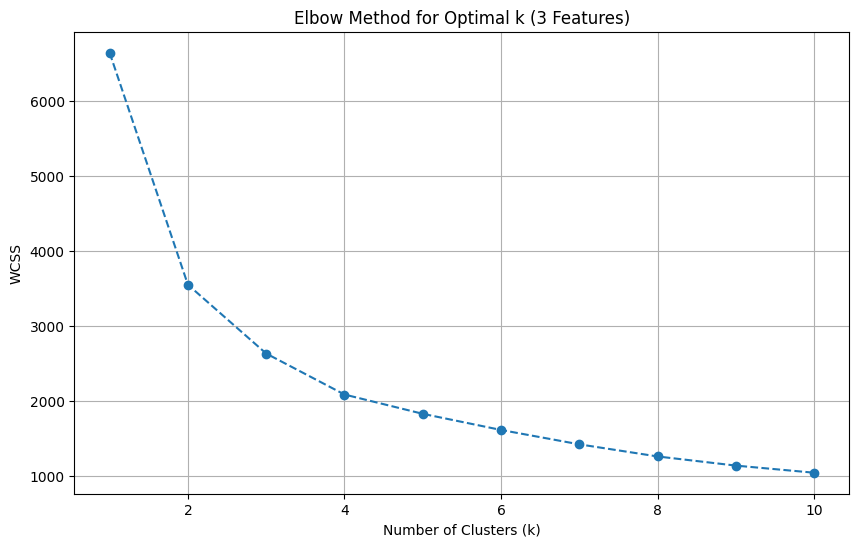

In [32]:
# Calculate WCSS (Within-Cluster Sum of Squares) for different k values for the 3-feature model
wcss_3_features = []
for i in range(1, 11): # Trying k from 1 to 10
    kmeans_3_features = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans_3_features.fit(data_3_features_scaled)
    wcss_3_features.append(kmeans_3_features.inertia_)

# Plotting the elbow method for the 3-feature model
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss_3_features, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k (3 Features)')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [37]:
# Build the KMeans model with the optimal number of clusters (k=3), based on the elbow method
kmeans_3_features = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
kmeans_3_features.fit(data_3_features_scaled)

# Assign the cluster labels to the log-transformed data
data_3_features_log['ClusterLabel'] = kmeans_3_features.labels_

# Display the first few rows with new cluster labels
display(data_3_features_log.head())

,Income,TotalAmountSpent,Age,ClusterLabel
0,10.970575,7.388328,4.234107,1
1,10.743847,3.295837,4.276666,0
2,11.179032,6.654153,4.110874,1
3,10.190394,3.970292,3.737670,0
4,10.973237,6.045005,3.806662,2


Now, let's summarize the clusters by calculating the median of the original (non-log-transformed) 'Income', 'TotalAmountSpent', and 'Age' for each cluster. This will help us understand the characteristics of each customer segment.

In [38]:
# Calculate the median values for each cluster using the log-transformed data
cluster_summary_3_features_log = data_3_features_log.groupby('ClusterLabel')[['Income', 'TotalAmountSpent', 'Age']].median()
# Convert log-transformed medians back to their original scale using np.exp()
actual_cluster_summary_3_features = np.exp(cluster_summary_3_features_log)
actual_cluster_summary_3_features.columns = ['Median_Income', 'Median_TotalAmountSpent', 'Median_Age']
display(actual_cluster_summary_3_features.round(2))

,Median_Income,Median_TotalAmountSpent,Median_Age
ClusterLabel,,,
0,31620.5,54.5,52.0
1,62972.0,835.0,69.0
2,67353.0,990.0,50.0


Let's visualize the median values for 'Income', 'TotalAmountSpent', and 'Age' for each cluster using bar charts to better understand their characteristics.

In [39]:
import plotly.graph_objects as go

# Create bar chart for Median Income by Cluster
fig_income_3 = px.bar(actual_cluster_summary_3_features.reset_index(),
                    x='ClusterLabel', y='Median_Income',
                    title='Median Income by Customer Cluster (3 Features)',
                    labels={'ClusterLabel': 'Cluster', 'Median_Income': 'Median Income'},
                    color='ClusterLabel')
fig_income_3.update_layout(xaxis_title_text='Cluster', yaxis_title_text='Median Income')
fig_income_3.show()

# Create bar chart for Median Total Amount Spent by Cluster
fig_spent_3 = px.bar(actual_cluster_summary_3_features.reset_index(),
                   x='ClusterLabel', y='Median_TotalAmountSpent',
                   title='Median Total Amount Spent by Customer Cluster (3 Features)',
                   labels={'ClusterLabel': 'Cluster', 'Median_TotalAmountSpent': 'Median Total Amount Spent'},
                   color='ClusterLabel')
fig_spent_3.update_layout(xaxis_title_text='Cluster', yaxis_title_text='Median Total Amount Spent')
fig_spent_3.show()

# Create bar chart for Median Age by Cluster
fig_age_3 = px.bar(actual_cluster_summary_3_features.reset_index(),
                 x='ClusterLabel', y='Median_Age',
                 title='Median Age by Customer Cluster (3 Features)',
                 labels={'ClusterLabel': 'Cluster', 'Median_Age': 'Median Age'},
                 color='ClusterLabel')
fig_age_3.update_layout(xaxis_title_text='Cluster', yaxis_title_text='Median Age')
fig_age_3.show()

#### Cluster Sizes and Visualization of 3-Feature Model

Let's also look at the sizes of the clusters and visualize them in a 3D scatter plot to get a better sense of their separation.

In [40]:
# Calculate and display the size of each cluster for the 3-feature model
cluster_sizes_3_features = data_3_features_log['ClusterLabel'].value_counts().sort_index()
print("Cluster sizes for 3-feature model (Income, TotalAmountSpent, Age):")
display(cluster_sizes_3_features)

# Plot the clusters in a 3D scatter plot (using log-transformed data for better visualization scale)
fig_3d_scatter = px.scatter_3d(data_3_features_log,
                               x='Income',
                               y='TotalAmountSpent',
                               z='Age',
                               color='ClusterLabel',
                               title='Customer Clusters (Log-transformed Income, Total Amount Spent, Age)',
                               labels={'Income': 'Log-transformed Income',
                                       'TotalAmountSpent': 'Log-transformed Total Amount Spent',
                                       'Age': 'Log-transformed Age',
                                       'ClusterLabel': 'Cluster'})
fig_3d_scatter.show()

Cluster sizes for 3-feature model (Income, TotalAmountSpent, Age):


,count
ClusterLabel,
0,850
1,756
2,609


## New clustering Analysis (2-Feature Model)

**Cluster 0: Value-Conscious Customers**

Characteristics: This cluster has a median income of approximately 32,301 and a median total amount spent of about $57. These customers represent a segment with lower income and very modest spending habits. They are likely highly price-sensitive and focused on essential purchases.
Marketing Strategy: Focus on value propositions, discounts, and promotions on necessary goods. Emphasize cost-effectiveness, durability, and practical benefits. Loyalty programs that reward small, frequent purchases could be effective. Communication should be clear, direct, and highlight savings.

**Cluster 1: Affluent Spenders**

Characteristics: This cluster has a significantly higher median income of approximately 65,324 and a median total amount spent of about $930. These customers are more affluent and demonstrate a much higher spending capacity. They likely value quality, convenience, and perhaps premium products or services.
Marketing Strategy: Highlight product quality, reliability, and benefits that justify a higher price point. Offer personalized recommendations, exclusive deals, and premium services. Loyalty programs that provide status or unique benefits could resonate well. Marketing messages can focus on lifestyle enhancement, convenience, and superior experience.

## New Clustering Analysis (3-Feature Model: Income, TotalAmountSpent, Age)

**Cluster 0: Young, Value-Conscious Customers**
*   **Characteristics:** Median Income ~\$31,620, Median TotalAmountSpent ~\$54, Median Age ~52. This cluster has the lowest income and spending among all clusters. While their median age is 52, they are relatively younger compared to Cluster 1. They are highly price-sensitive and likely focus on essential goods.
*   **Marketing Strategy:** Focus on promotions, discounts, and value-for-money products. Emphasize practicality and cost-effectiveness. Targeted digital advertising on budget-friendly platforms could be effective. Consider loyalty programs that reward frequent, smaller purchases.

**Cluster 1: Older, Established, High-Value Spenders**
*   **Characteristics:** Median Income ~\$62,972, Median TotalAmountSpent ~\$835, Median Age ~69. This cluster represents older customers with a good income and substantial spending habits, though their median income is slightly lower than Cluster 2. They likely value established brands, reliability, and comfortable shopping experiences.
*   **Marketing Strategy:** Offer products that cater to their age group's needs and preferences, such as health-related products, comfort items, or services that simplify their lives. Focus on customer service, brand loyalty, and personalized experiences. Marketing efforts could involve direct mail, traditional media, and personalized email campaigns highlighting premium yet reliable products.

**Cluster 2: Affluent, Active, Mid-Aged Spenders**
*   **Characteristics:** Median Income ~\$67,353, Median TotalAmountSpent ~\$990, Median Age ~50. This cluster has the highest median income and total amount spent, and is in the mid-age range. They are affluent, active, and likely willing to spend on quality, convenience, and perhaps luxury items or experiences.
*   **Marketing Strategy:** Target with premium products, exclusive offers, and convenience-oriented services. Emphasize quality, status, and unique experiences. Digital marketing, social media campaigns focusing on lifestyle, and partnerships with luxury brands could be highly effective. Personalized recommendations and early access to new products would also appeal to this segment.